# 03 — Review timelines

Monthly review history for the most-reviewed games (`stp fetch timelines`), analyzed by `stp analyze`:

- **launch** score: first 3 months, extended up to 6 until there are at least 50 reviews. Blank for games older than Steam reviews (Oct 2010).
- **recent** score: last 12 months. **drift** = recent − launch.
- **trough / peak**: lowest and highest 3-month rolling score after launch. **recovery** = recent − trough.
- **turning points**: PELT change points on the monthly positive %, keeping shifts of at least 5 pp, matched to the nearest update or launch announcement within ±45 days.

This notebook checks the turning points against known events and looks at the aggregate patterns.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

con = duckdb.connect("../data/analysis.duckdb", read_only=True)
pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(70)
plt.rcParams.update(
    {"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False}
)


def q(sql, params=None):
    return con.sql(sql, params=params).pl()


q("""
SELECT COUNT(*) AS games, SUM(total_reviews) AS reviews, SUM(n_changes) AS turning_points,
       (SELECT COUNT(*) FROM timeline_changes WHERE news_title IS NOT NULL) AS matched_to_news,
       SUM((launch_score IS NULL)::INT) AS no_launch_score
FROM timeline_games
""")

games,reviews,turning_points,matched_to_news,no_launch_score
i64,"decimal[38,0]","decimal[38,0]",i64,"decimal[38,0]"
1000,120551616,2234,1235,51


## 1. Known events: do the turning points find them?

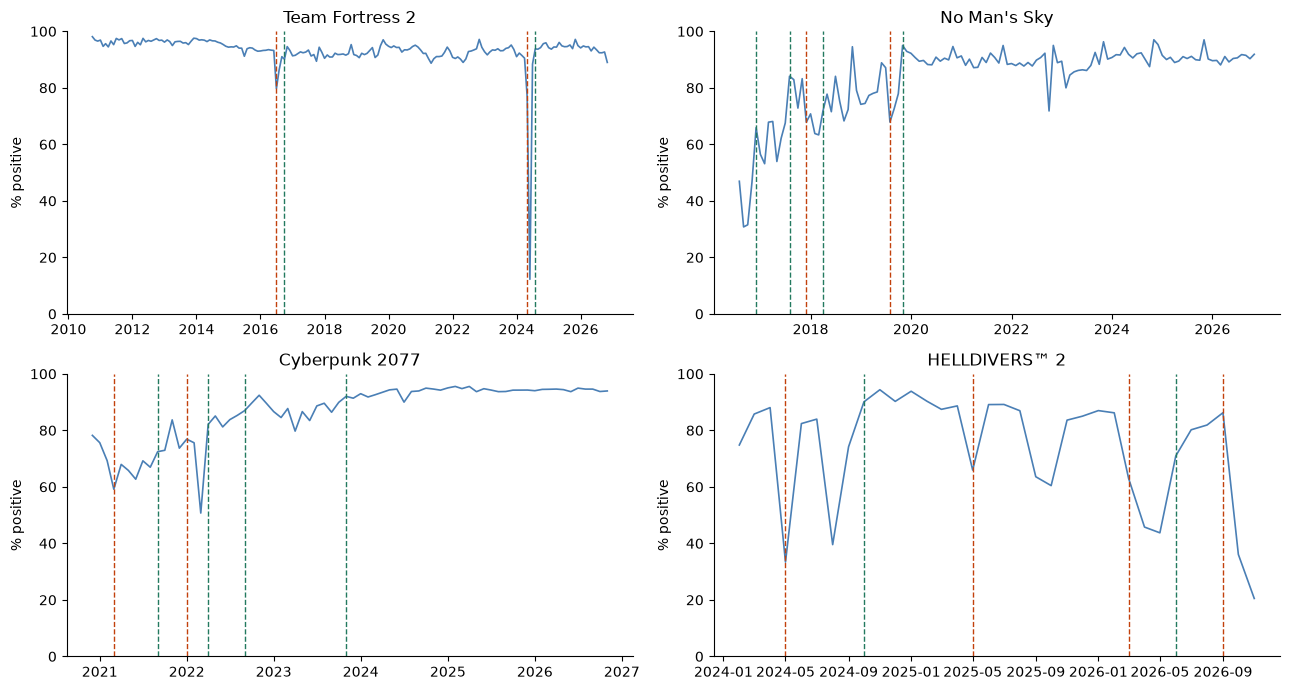

In [2]:
def plot_game(name_like, ax=None):
    appid, name = con.execute(
        "SELECT appid, name FROM games WHERE name ILIKE ? AND appid IN (SELECT appid FROM timeline_games) "
        "ORDER BY review_count DESC LIMIT 1",
        [name_like],
    ).fetchall()[0]
    m = q(
        "SELECT month, up, down FROM review_monthly WHERE appid = $a ORDER BY month", {"a": appid}
    )
    ch = q(
        "SELECT month, before, after, news_title FROM timeline_changes WHERE appid = $a",
        {"a": appid},
    )
    n = m["up"] + m["down"]
    pct = np.array((100 * m["up"] / n).to_numpy(), dtype=float)
    pct[n.to_numpy() < 20] = np.nan
    ax = ax or plt.gca()
    ax.plot(m["month"], pct, lw=1.2, color="#4a7fb5")
    for row in ch.iter_rows(named=True):
        ax.axvline(
            row["month"],
            color="#c2410c" if row["after"] < row["before"] else "#237a5f",
            lw=1,
            ls="--",
        )
    ax.set(title=name, ylim=(0, 100), ylabel="% positive")
    return ch


fig, axes = plt.subplots(2, 2, figsize=(13, 7))
out = {}
for ax, g in zip(
    axes.flat, ["Team Fortress 2", "No Man%Sky", "Cyberpunk 2077", "HELLDIVERS%2"], strict=True
):
    out[g] = plot_game(g, ax)
plt.tight_layout()
plt.show()

In [3]:
pl.concat([df.with_columns(pl.lit(g).alias("game")) for g, df in out.items()]).select(
    "game", "month", pl.col("before").round(1), pl.col("after").round(1), "news_title"
)

game,month,before,after,news_title
str,date,f64,f64,str
"""Team Fortress 2""",2016-07-01,93.7,84.3,null
"""Team Fortress 2""",2016-10-01,84.3,92.6,null
"""Team Fortress 2""",2024-05-01,91.4,30.4,"""Team Fortress 2 Update Released"""
"""Team Fortress 2""",2024-08-01,30.4,94.7,"""Team Fortress 2 Update Released"""
"""No Man%Sky""",2016-12-01,44.3,63.7,"""Patch 1.13"""
"""No Man%Sky""",2017-08-01,63.7,83.2,"""Atlas Rises Patch 1.31"""
"""No Man%Sky""",2017-12-01,83.2,67.0,null
"""No Man%Sky""",2018-04-01,67.0,79.5,"""No Man's Sky NEXT Multiplayer and Release Date"""
"""No Man%Sky""",2019-08-01,86.7,69.7,"""No Man's Sky BEYOND - OUT NOW!"""


## 2. Biggest swings

The largest turning points across all games, with the matched announcement when there is one. Large negative shifts with no update nearby are usually review bombs or external events (pricing, platform requirements, publisher controversies).

In [4]:
q("""
SELECT g.name, tc.month, round(tc.before, 1) AS before, round(tc.after, 1) AS after,
       round(tc.shift, 1) AS shift, tc.news_title
FROM timeline_changes tc JOIN games g USING (appid)
ORDER BY abs(tc.shift) DESC LIMIT 25
""")

name,month,before,after,shift,news_title
str,date,f64,f64,f64,str
"""鬼谷八荒 Tale of Immortal""",2022-04-01,89.3,4.2,-85.1,"""[0.8.5018] MOD Maker(1.0 BETA) Now On!"""
"""Europa Universalis IV""",2026-09-01,87.4,4.9,-82.4,null
"""Crusader Kings II""",2026-09-01,86.0,6.3,-79.7,null
"""Borderlands 2""",2025-04-01,93.7,17.1,-76.6,null
"""Hearts of Iron IV""",2026-09-01,87.7,11.4,-76.3,"""HOI IV | Patch 1.19.3"""
"""Blue Archive""",2026-06-01,91.0,17.6,-73.4,"""(Updated on 6/9) June Update Special Survey!"""
"""Prison Architect""",2026-09-01,81.5,9.3,-72.2,null
"""Cities: Skylines""",2026-09-01,90.7,18.5,-72.2,null
"""Mirror 2: Project X""",2022-09-01,75.1,5.6,-69.5,"""20220915 UPDATE NOTE"""


## 3. Drift: do games get better or worse after launch?

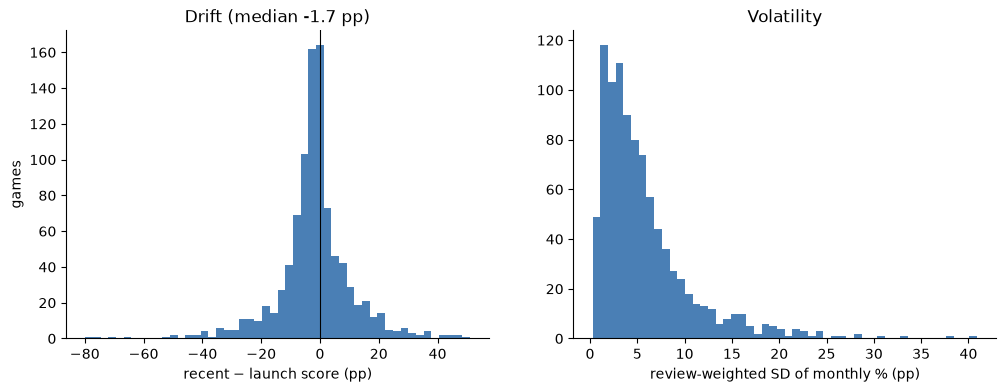

In [5]:
t = q("SELECT drift, recovery, decline, volatility FROM timeline_games WHERE drift IS NOT NULL")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(t["drift"], bins=50, color="#4a7fb5")
ax[0].axvline(0, color="black", lw=0.8)
ax[0].set(
    xlabel="recent − launch score (pp)",
    ylabel="games",
    title=f"Drift (median {t['drift'].median():+.1f} pp)",
)
ax[1].hist(t["volatility"].drop_nulls(), bins=50, color="#4a7fb5")
ax[1].set(xlabel="review-weighted SD of monthly % (pp)", title="Volatility")
plt.show()

In [6]:
cols = "g.name, tg.first_month, round(tg.launch_score, 1) AS launch, round(tg.trough_score, 1) AS trough, round(tg.recent_score, 1) AS recent"
print("Biggest comebacks (recent − trough)")
display(
    q(
        f"SELECT {cols}, round(tg.recovery, 1) AS recovery FROM timeline_games tg JOIN games g USING (appid) WHERE tg.recovery IS NOT NULL ORDER BY tg.recovery DESC LIMIT 12"
    )
)
print("Biggest declines (peak − recent)")
display(
    q(
        f"SELECT {cols}, round(tg.decline, 1) AS decline FROM timeline_games tg JOIN games g USING (appid) WHERE tg.decline IS NOT NULL ORDER BY tg.decline DESC LIMIT 12"
    )
)

Biggest comebacks (recent − trough)


name,first_month,launch,trough,recent,recovery
str,date,f64,f64,f64,f64
"""Russian Fishing 4""",2018-06-01,69.5,8.3,85.3,76.9
"""鬼谷八荒 Tale of Immortal""",2021-01-01,88.4,4.2,76.9,72.7
"""Borderlands 2""",2012-09-01,98.0,17.1,88.6,71.5
"""Team Fortress 2""",2010-10-01,null,27.2,93.7,66.5
"""Skullgirls 2nd Encore""",2013-08-01,98.3,24.0,87.6,63.6
"""Legend of Mortal""",2024-06-01,72.1,30.1,93.0,62.9
"""Borderlands: The Pre-Sequel""",2014-10-01,81.4,15.4,78.0,62.6
"""Total War: ROME II - Emperor Edition""",2013-09-01,80.1,29.2,89.6,60.4
"""Total War: WARHAMMER III""",2022-02-01,59.5,19.7,79.5,59.8


Biggest declines (peak − recent)


name,first_month,launch,trough,recent,decline
str,date,f64,f64,f64,f64
"""Europa Universalis IV""",2013-08-01,96.7,4.9,19.8,74.8
"""Crusader Kings II""",2012-02-01,95.7,6.3,25.9,74.1
"""Mirror 2: Project X""",2022-01-01,96.4,4.9,16.6,73.6
"""Prison Architect""",2013-03-01,97.0,9.3,32.0,67.6
"""Hearts of Iron IV""",2016-06-01,82.4,11.4,37.6,58.4
"""New World: Aeternum""",2021-09-01,68.5,17.7,26.0,57.5
"""Kerbal Space Program 2""",2023-02-01,51.8,6.5,23.4,52.7
"""Blue Archive""",2025-07-01,91.0,13.8,41.2,52.2
"""The Scroll of Taiwu : Beyond The Dome""",2018-09-01,89.2,27.0,40.0,51.2


## 4. Average trajectory by primary tag

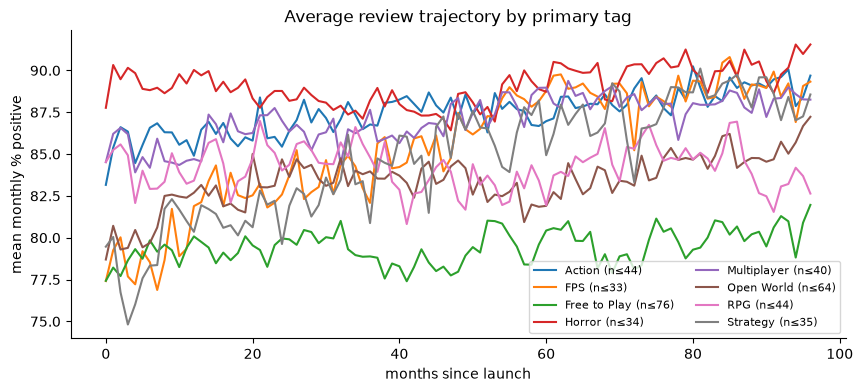

In [7]:
curves = q("""
SELECT t.name, c.months_since_launch AS m, c.mean_pct, c.n_games FROM tag_curves c JOIN tags t USING (tagid)
WHERE c.tagid IN (SELECT tagid FROM tag_curves GROUP BY tagid ORDER BY MAX(n_games) DESC LIMIT 8)
ORDER BY t.name, m
""")
for name, df in curves.group_by("name", maintain_order=True):
    plt.plot(df["m"], df["mean_pct"], label=f"{name[0]} (n≤{df['n_games'].max()})")
plt.xlabel("months since launch")
plt.ylabel("mean monthly % positive")
plt.legend(fontsize=8, ncol=2)
plt.title("Average review trajectory by primary tag")
plt.show()

## Takeaways (first pass, 2026-11-18)

- **Coverage:** all 1,000 games, 120M reviews. Newer games come back as weekly rollups and are summed into months. 51 games predate Steam reviews (Oct 2010) and get no launch score.
- **Turning points find real history.** No Man's Sky's comeback lines up with Pathfinder, Atlas Rises, NEXT, Beyond and Synthesis. Cyberpunk 2077's dips and recoveries line up with patches 1.2, 1.5, 1.6 (Edgerunners) and 2.1. TF2 shows the 2016 Meet Your Match dip and the 2024 bot-crisis drop and recovery.
- **A match is proximity, not cause.** 55% of the 2,234 turning points have an update or launch announcement within ±45 days, but several of the biggest swings are external events: Helldivers 2's May 2024 drop was the PSN-account controversy, yet it got paired with an ordinary patch. The site should say "nearest announcement" and never imply a cause.
- **Review bombs dominate the extremes.** The largest drops are publisher-wide or policy-driven, e.g. the September 2026 collapse across Paradox titles (EU4, CK2, CK3, HoI4, Cities: Skylines, Prison Architect) and Borderlands 2 / Pre-Sequel in April 2025, not ordinary patches. These are worth their own callout on the Findings page.
- **Comebacks are common among big games:** Russian Fishing 4, Borderlands 2, TF2, Total War: Warhammer III, No Man's Sky and War Thunder all climbed back more than 50 pp from their trough.